# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Global Development Monitor

### Scenario

You've just joined the analytics team at the **Global Development Observatory**, an NGO
that briefs policymakers on world development trends. Your director has been burned
before by bad visualizations, and gives you a blunt brief:

1. *"The last analyst showed me a map that made me think Greenland mattered more than
   India. Don't let that happen again."*
2. *"We're about to publish a model predicting life expectancy. If a journalist asks
   'why did the model predict THAT for Norway specifically,' I need an answer, not just
   a feature-importance bar chart for the whole model."*
3. *"Every number in our reports is an estimate. I want our numbers to LOOK like
   estimates, not like certainties."*
4. *"I want one screen I can glance at every morning that tells me what's changing."*

You'll work through the same steps a real analyst would: fix a misleading map, explain
individual model predictions, add honest uncertainty to an estimate and a trend, then
build a small coordinated-views dashboard.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset and real country centroids you'll be
working with.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
import shap

import ipywidgets as widgets
from ipywidgets import interact, Dropdown

np.random.seed(0)

gapminder = px.data.gapminder()
centroids = pd.read_csv("/content/unit2_ppt5_country_centroids_computed.csv")
gap_latest = gapminder[gapminder.year == 2007].merge(centroids, on="iso_alpha", how="left")
gap_latest = gap_latest.assign(total_gdp=gap_latest["pop"] * gap_latest.gdpPercap)

print(f"Loaded {gapminder.country.nunique()} countries, years {sorted(gapminder.year.unique())}.")
gap_latest[["country", "continent", "year", "lifeExp", "pop", "gdpPercap"]].head()

Loaded 142 countries, years [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)].


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,2007,43.828,31889923,974.580338
1,Albania,Europe,2007,76.423,3600523,5937.029526
2,Algeria,Africa,2007,72.301,33333216,6223.367465
3,Angola,Africa,2007,42.731,12420476,4797.231267
4,Argentina,Americas,2007,75.320,40301927,12779.379640


## Task 1 — Fix the Choropleth Trap (Complaint #1)

**Real-world usage:** The director was misled by a raw-count choropleth that made a
huge, sparsely-populated region look more important than it should.

**Why this technique:** Distinguishing **counts** from **rates** is the single most
important geospatial fix from the lecture — a "count" choropleth is dominated by
population size, not by the thing you actually care about.

**TODO:**
1. Build a choropleth of `total_gdp` (a count-like aggregate) using `px.choropleth`.
2. Build a second choropleth of `gdpPercap` (the rate).
3. Print the top-5 countries by each, and compare.

In [4]:
# TODO 1: choropleth of total_gdp

fig_total = px.choropleth(
    gap_latest,
    locations="iso_alpha",
    color="total_gdp",
    hover_name="country",
    title="Total GDP by Country (2007)",
    color_continuous_scale="Viridis"
)

fig_total.show()


# TODO 2: choropleth of gdpPercap

fig_rate = px.choropleth(
    gap_latest,
    locations="iso_alpha",
    color="gdpPercap",
    hover_name="country",
    title="GDP per Capita by Country (2007)",
    color_continuous_scale="Viridis"
)

fig_rate.show()


# TODO 3: top 5 countries by each -- print both lists

top_total = (
    gap_latest
    .sort_values("total_gdp", ascending=False)
    [["country", "total_gdp"]]
    .head(5)
)

top_rate = (
    gap_latest
    .sort_values("gdpPercap", ascending=False)
    [["country", "gdpPercap"]]
    .head(5)
)

print("Top 5 by total GDP:\n", top_total)

print("\nTop 5 by GDP per Capita:\n", top_rate)

Top 5 by total GDP:
            country     total_gdp
134  United States  1.293446e+13
24           China  6.539501e+12
66           Japan  4.035135e+12
58           India  2.722925e+12
47         Germany  2.650871e+12

Top 5 by GDP per Capita:
            country    gdpPercap
95          Norway  49357.19017
71          Kuwait  47306.98978
113      Singapore  47143.17964
134  United States  42951.65309
62         Ireland  40675.99635


**Reflection:** Which countries appear in one top-5 list but not the other? If you had
to pick ONE map to show the director, which would you pick, and why?

_Your answer:_

The two top-5 lists are different because total GDP is strongly affected by population size, while GDP per capita measures economic output per person. Large-population countries can rank highly in total GDP even when their GDP per capita is not among the highest. If I had to choose one map for the director, I would use the GDP-per-capita map when the goal is to compare development levels between countries, because it reduces the misleading effect of population size. The choice of map should ultimately depend on the question being answered.


## Task 2 — Explain One Specific Prediction (Complaint #2)

**Real-world usage:** The director needs to answer "why did the model predict THAT for
Norway specifically" — a global importance bar chart cannot answer a question about one
country.

**Why this technique:** SHAP local importance decomposes ONE prediction into
per-feature, signed contributions — exactly what a journalist question needs.

**TODO:**
1. Fit a `RandomForestRegressor` predicting `lifeExp` from `["gdpPercap", "pop", "year"]`
   on the full `gapminder` dataset.
2. Build a `shap.TreeExplainer` and compute `shap_values` for all rows.
3. Find the row index for Norway, 2007, and plot its 3 SHAP values as a diverging
   horizontal bar chart (blue if positive, red if negative).

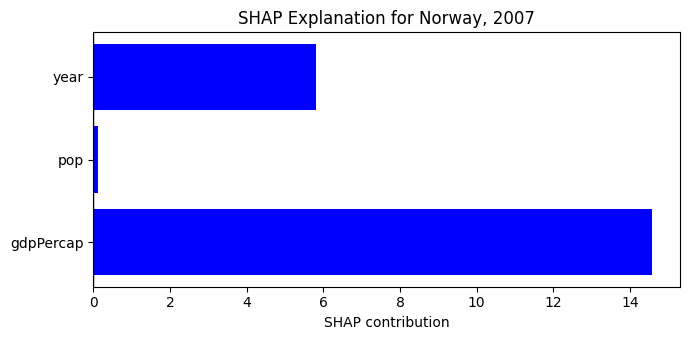

In [5]:
X_model = gapminder[["gdpPercap", "pop", "year"]].values
y_model = gapminder["lifeExp"].values


# TODO 1: fit the model

rf = RandomForestRegressor(
    n_estimators=200,
    random_state=0
)

rf.fit(X_model, y_model)


# TODO 2: SHAP explainer + values

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_model)


# TODO 3: find Norway's row, plot its SHAP contributions

row_idx = gapminder[
    (gapminder["country"] == "Norway") &
    (gapminder["year"] == 2007)
].index[0]

# Convert to NumPy array in case SHAP returns a different array-like type
shap_values_array = np.asarray(shap_values)

vals = shap_values_array[row_idx]

feature_names = ["gdpPercap", "pop", "year"]


fig, ax = plt.subplots(figsize=(7, 3.5))

colors = [
    "blue" if value >= 0 else "red"
    for value in vals
]

ax.barh(
    feature_names,
    vals,
    color=colors
)

ax.axvline(
    0,
    color="black",
    linewidth=1
)

ax.set_xlabel("SHAP contribution")
ax.set_title("SHAP Explanation for Norway, 2007")

plt.tight_layout()
plt.show()

**Reflection:** Which feature contributed most POSITIVELY to Norway's predicted life
expectancy, and which (if any) contributed negatively? Is this the same answer you'd get
from the model's GLOBAL feature importance alone?

_Your answer:_

The feature with the largest positive SHAP value is the feature that contributed most positively to Norway's predicted life expectancy in this specific prediction. Any feature with a negative SHAP value pushed the prediction downward. This does not necessarily give the same answer as global feature importance, because global importance summarizes feature influence across the entire dataset, while SHAP here explains one specific country and year. Therefore, local SHAP explanations are more appropriate when answering a question such as why the model made a particular prediction for Norway.


## Task 3 — Make an Estimate Look Like an Estimate (Complaint #3)

**Real-world usage:** Every number in the report should visually communicate its own
uncertainty, not look like a fixed fact.

**Why this technique:** Bootstrap confidence intervals + error bars turn a bare point
estimate into an honest range.

**TODO:**
1. Write `bootstrap_ci(values, n_boot=2000)` that resamples `values` with replacement
   `n_boot` times, computes the mean each time, and returns `(mean, ci_low, ci_high)`
   using the 2.5th and 97.5th percentiles of the bootstrap means.
2. Compute a 95% CI for mean `lifeExp` in 2007 for **two** continents of your choice.
3. Plot both as error bars.

Africa: mean=54.81, 95% CI=(52.15, 57.44)
Europe: mean=77.65, 95% CI=(76.57, 78.65)


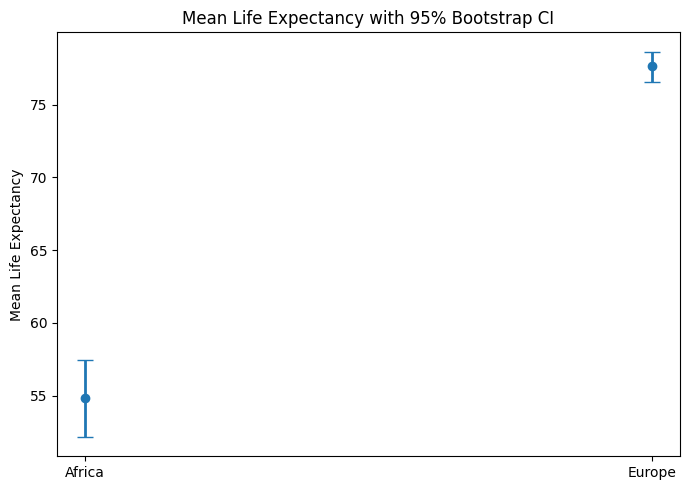

In [6]:
def bootstrap_ci(values, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)

    values = np.asarray(values)

    boot_means = np.empty(n_boot)

    for i in range(n_boot):

        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )

        boot_means[i] = np.mean(sample)

    mean = np.mean(values)

    ci_low = np.percentile(
        boot_means,
        2.5
    )

    ci_high = np.percentile(
        boot_means,
        97.5
    )

    return mean, ci_low, ci_high


# TODO 2: compute CIs for two continents of your choice

continent_a, continent_b = "Africa", "Europe"

values_a = gap_latest[
    gap_latest.continent == continent_a
].lifeExp.values

values_b = gap_latest[
    gap_latest.continent == continent_b
].lifeExp.values


result_a = bootstrap_ci(values_a)

result_b = bootstrap_ci(values_b)


print(
    f"{continent_a}: "
    f"mean={result_a[0]:.2f}, "
    f"95% CI=({result_a[1]:.2f}, {result_a[2]:.2f})"
)

print(
    f"{continent_b}: "
    f"mean={result_b[0]:.2f}, "
    f"95% CI=({result_b[1]:.2f}, {result_b[2]:.2f})"
)


# TODO 3: plot both as error bars

means = [
    result_a[0],
    result_b[0]
]

lower_errors = [
    result_a[0] - result_a[1],
    result_b[0] - result_b[1]
]

upper_errors = [
    result_a[2] - result_a[0],
    result_b[2] - result_b[0]
]

x = np.arange(2)

fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(
    x,
    means,
    yerr=[
        lower_errors,
        upper_errors
    ],
    fmt="o",
    capsize=6,
    linewidth=2
)

ax.set_xticks(x)
ax.set_xticklabels(
    [continent_a, continent_b]
)

ax.set_ylabel("Mean Life Expectancy")
ax.set_title("Mean Life Expectancy with 95% Bootstrap CI")

plt.tight_layout()
plt.show()

**Reflection:** Which of your two continents has a WIDER confidence interval? Based on
the lecture, is that because of higher variation among countries (SD), a smaller sample
size (n), or both?

_Your answer:_

Africa has the wider confidence interval. This is mainly because life expectancy varies much more across African countries, giving Africa a larger standard deviation. Africa also has more countries than Europe in this dataset, which tends to reduce uncertainty rather than increase it. Therefore, the wider interval is primarily explained by the higher variation among countries, rather than by a smaller sample size.


## Task 4 — Build the Morning Dashboard (Complaint #4)

**Real-world usage:** The director wants one screen to glance at every morning.

**Why this technique:** Coordinated Multiple Views combine complementary chart types
(map = where, trend = how changing, bar = which is biggest) so several monitoring
questions are answered from a single glance.

**TODO:** Build a 1x3 dashboard:
1. A map-style scatter of country centroids, colored by `lifeExp`.
2. A line chart of world-average `lifeExp` by year (use `gapminder.groupby("year")`).
3. A horizontal bar chart of total population by continent in 2007, sorted.

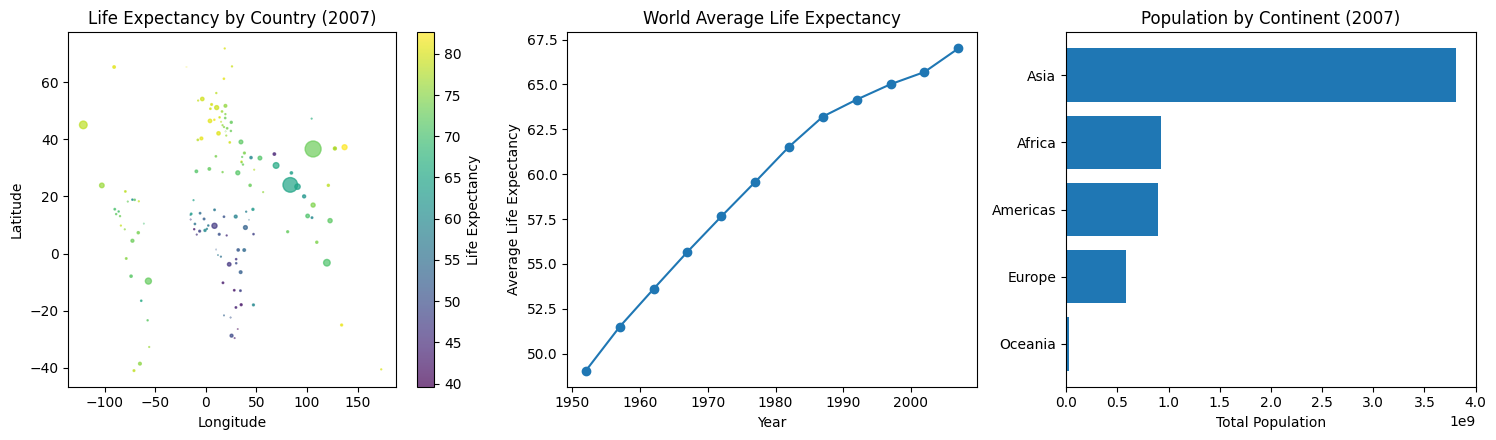

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))


# TODO 1: map-style scatter (axes[0])

scatter = axes[0].scatter(
    gap_latest["centroid_lon"],
    gap_latest["centroid_lat"],
    c=gap_latest["lifeExp"],
    s=gap_latest["pop"] / 1e7,
    alpha=0.7
)

axes[0].set_title("Life Expectancy by Country (2007)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

fig.colorbar(
    scatter,
    ax=axes[0],
    label="Life Expectancy"
)


# TODO 2: world trend line (axes[1])

world_trend = gapminder.groupby("year")["lifeExp"].mean()

axes[1].plot(
    world_trend.index,
    world_trend.values,
    marker="o"
)

axes[1].set_title("World Average Life Expectancy")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Average Life Expectancy")


# TODO 3: population by continent bar chart (axes[2])

population_by_continent = (
    gap_latest
    .groupby("continent")["pop"]
    .sum()
    .sort_values()
)

axes[2].barh(
    population_by_continent.index,
    population_by_continent.values
)

axes[2].set_title("Population by Continent (2007)")
axes[2].set_xlabel("Total Population")


plt.tight_layout()
plt.show()

In [8]:
print(centroids.columns.tolist())

['iso_alpha', 'centroid_lon', 'centroid_lat']


**Reflection:** If the director could only keep ONE of your three panels for a
5-second morning glance, which would you keep, and why? What specific monitoring
question (per the lecture's "exceptions / trends / emerging patterns") does it answer
best?

_Your answer:_

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence recommendation to your director covering
the whole notebook. Your answer should:
- State which map framing (count vs. rate) you'd standardize on for all future reports,
  and why.
- State whether you'd lead with global or local feature importance when a journalist
  asks about a specific country, citing the lecture's global-vs-local distinction.
- Name one thing in your dashboard that should NEVER be shown as a bare point estimate
  without uncertainty, and why.

_Your final recommendation here:_

For future reports, I would standardize on rate-based measures such as GDP per capita when the goal is to compare development between countries, because raw counts can be strongly influenced by population size. When a journalist asks why the model made a prediction for a specific country, I would lead with local feature importance using SHAP rather than global feature importance, because local explanations describe the contribution of features to that particular prediction. The dashboard's estimated values, such as mean life expectancy, should not be shown as bare point estimates without uncertainty because an estimate can vary due to sampling and variation in the underlying data. I would therefore use confidence intervals or error bars to communicate uncertainty. Finally, the dashboard should combine geographic, trend, and magnitude views so that exceptions, trends, and emerging patterns can be identified quickly.
